In [1]:
import os
import glob
import math
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

In [2]:
!nvidia-smi

Mon Nov  2 12:54:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.88                 KMD Version: 610.88        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   39C    P0            312W /   60W |       0MiB /   6144MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


In [5]:
DATA_DIR = "./shakespeare-plays"  # Change this to your extracted Kaggle dataset folder
SEQ_LEN = 128
BATCH_SIZE = 64
MAX_EPOCHS = 20
LEARNING_RATE = 3e-4
QUICK_RUN = False  # True = smaller/faster run for testing
if QUICK_RUN:
    BATCH_SIZE = 32
    MAX_EPOCHS = 2

os.makedirs("task2_outputs", exist_ok=True)

## Load the Shakespeare text

In [6]:
TEXT_COLUMNS = ["text", "content", "play", "script", "line", "dialogue"]

def load_shakespeare_text(folder):
    parts = []
    files = glob.glob(os.path.join(folder, "**", "*"), recursive=True)
    for path in files:
        if not os.path.isfile(path):
            continue
        ext = os.path.splitext(path)[1].lower()
        try:
            if ext == ".txt":
                with open(path, "r", encoding="utf-8", errors="ignore") as f:
                    value = f.read()
                if value.strip():
                    parts.append(value)
            elif ext == ".csv":
                frame = pd.read_csv(path)
                cols = [c for c in frame.columns if str(c).lower() in TEXT_COLUMNS]
                if not cols:
                    cols = [c for c in frame.columns if frame[c].dtype == "object"]
                for col in cols:
                    parts.extend(frame[col].dropna().astype(str).tolist())
        except Exception as e:
            print("Skipped:", path, "|", e)
    if not parts:
        raise FileNotFoundError("No readable .txt or .csv text found. Check DATA_DIR and the extracted dataset.")
    return "\n".join(parts)

text_data = load_shakespeare_text(DATA_DIR)
print("Characters:", len(text_data))
print(text_data[:500])

Characters: 6248564
"ACT I"
"SCENE I. London. The palace."
"Enter KING HENRY, LORD JOHN OF LANCASTER, the EARL of WESTMORELAND, SIR WALTER BLUNT, and others"
"So shaken as we are, so wan with care,"
"Find we a time for frighted peace to pant,"
"And breathe short-winded accents of new broils"
"To be commenced in strands afar remote."
"No more the thirsty entrance of this soil"
"Shall daub her lips with her own children's blood,"
"Nor more shall trenching war channel her fields,"
"Nor bruise her flowerets with the ar


## Character-level tokenizer and train/validation split

In [13]:
chars = sorted(list(set(text_data)))
vocab_size = len(chars)
stoi = {ch:i for i, ch in enumerate(chars)}
itos = {i:ch for i, ch in enumerate(chars)}

def encode(s):
    return [stoi[ch] for ch in s if ch in stoi]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

all_ids = torch.tensor(encode(text_data), dtype=torch.long)
split = int(0.9 * len(all_ids))
train_ids = all_ids[:split]
val_ids = all_ids[split:]

print("Vocabulary size:", vocab_size)
print("Train characters:", len(train_ids))
print("Validation characters:", len(val_ids))

class TextWindows(Dataset):
    def __init__(self, ids, seq_len):
        self.ids = ids
        self.seq_len = seq_len

    def __len__(self):
        return (len(self.ids) - 1) // self.seq_len

    def __getitem__(self, idx):
        start = idx * self.seq_len
        x = self.ids[start:start+self.seq_len]
        y = self.ids[start+1:start+self.seq_len+1]
        return x, y

train_loader = DataLoader(
    TextWindows(train_ids, SEQ_LEN),
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)

val_loader = DataLoader(
    TextWindows(val_ids, SEQ_LEN),
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Vocabulary size: 78
Train characters: 5623707
Validation characters: 624857
Training batches: 686
Validation batches: 76


## Positional encodings

In [14]:
class SinusoidalPosition(nn.Module):
    def __init__(self, seq_len, d_model):
        super().__init__()
        pos = torch.arange(seq_len).float().unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe = torch.zeros(1, seq_len, d_model)
        pe[0, :, 0::2] = torch.sin(pos * div)
        if d_model > 1:
            pe[0, :, 1::2] = torch.cos(pos * div[:pe[0, :, 1::2].shape[-1]])
        self.register_buffer("pe", pe)
    def forward(self, x):
        return self.pe[:, :x.size(1), :]

class LearnedPosition(nn.Module):
    def __init__(self, seq_len, d_model):
        super().__init__()
        self.embedding = nn.Embedding(seq_len, d_model)
    def forward(self, x):
        positions = torch.arange(x.size(1), device=x.device)
        return self.embedding(positions).unsqueeze(0)

## Multi-head causal self-attention


In [15]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, seq_len, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        mask = torch.tril(torch.ones(seq_len, seq_len))
        self.register_buffer("causal_mask", mask.view(1, 1, seq_len, seq_len))

    def forward(self, x, return_attention=False):
        batch, length, channels = x.shape
        q = self.q_proj(x).view(batch, length, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(batch, length, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(batch, length, self.n_heads, self.head_dim).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        mask = self.causal_mask[:, :, :length, :length]
        scores = scores.masked_fill(mask == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)
        output = weights @ v
        output = output.transpose(1, 2).contiguous().view(batch, length, channels)
        output = self.out_proj(output)
        if return_attention:
            return output, weights
        return output

class FeedForward(nn.Module):
    def __init__(self, d_model, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, 4*d_model),
            nn.GELU(),
            nn.Linear(4*d_model, d_model),
            nn.Dropout(dropout)
        )
    def forward(self, x):
        return self.net(x)

class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, seq_len, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attention = CausalSelfAttention(d_model, n_heads, seq_len, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, dropout)
    def forward(self, x, return_attention=False):
        if return_attention:
            attn_out, weights = self.attention(self.ln1(x), True)
            x = x + attn_out
            x = x + self.ffn(self.ln2(x))
            return x, weights
        x = x + self.attention(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x

## Decoder-only model

In [16]:
class GPTLanguageModel(nn.Module):
    def __init__(self, vocab_size, seq_len=128, d_model=128, n_heads=4, n_layers=4, position_type="learned", dropout=0.1):
        super().__init__()
        self.seq_len = seq_len
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        if position_type == "learned":
            self.position_embedding = LearnedPosition(seq_len, d_model)
        elif position_type == "sinusoidal":
            self.position_embedding = SinusoidalPosition(seq_len, d_model)
        else:
            raise ValueError("position_type must be learned or sinusoidal")
        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads, seq_len, dropout) for _ in range(n_layers)
        ])
        self.final_ln = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size)

    def forward(self, idx, targets=None, return_attention=False):
        x = self.token_embedding(idx) + self.position_embedding(idx)
        attention_map = None
        for i, block in enumerate(self.blocks):
            if return_attention and i == 0:
                x, attention_map = block(x, True)
            else:
                x = block(x)
        logits = self.lm_head(self.final_ln(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        if return_attention:
            return logits, loss, attention_map
        return logits, loss

## Training and validation

In [17]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    losses = []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        _, loss = model(x, y)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses)) if losses else float("nan")

def train_model(config, save_name=None):
    model = GPTLanguageModel(
        vocab_size=vocab_size, seq_len=SEQ_LEN,
        d_model=config["d_model"], n_heads=config["heads"],
        n_layers=config["layers"], position_type=config["position"]
    ).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    train_history, val_history = [], []
    previous_loss = None
    start_time = time.time()

    for epoch in range(MAX_EPOCHS):
        model.train()
        batch_losses = []
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            _, loss = model(x, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = float(np.mean(batch_losses))
        val_loss = evaluate(model, val_loader)
        train_history.append(train_loss)
        val_history.append(val_loss)
        print(f"Epoch {epoch+1:02d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val PPL {math.exp(min(val_loss, 20)):.2f}")

        if previous_loss is not None and abs(train_loss - previous_loss) < 1e-4:
            print("Convergence criterion reached.")
            break
        previous_loss = train_loss

    elapsed = time.time() - start_time
    if save_name:
        torch.save({"model": model.state_dict(), "config": config}, f"task2_outputs/{save_name}.pt")
    return model, train_history, val_history, elapsed

## Run all baseline configurations

In [18]:
baseline_configs = []
for layers in [2, 4]:
    for heads in [2, 4]:
        for d_model in [64, 128]:
            for position in ["learned", "sinusoidal"]:
                baseline_configs.append({
                    "layers": layers, "heads": heads,
                    "d_model": d_model, "position": position
                })

results = []
models = {}
for number, config in enumerate(baseline_configs, 1):
    name = f"baseline_{number:02d}"
    print("\nConfiguration", number, "/", len(baseline_configs), config)
    model, train_hist, val_hist, seconds = train_model(config, name)
    key = (config["layers"], config["heads"], config["d_model"], config["position"])
    models[key] = model
    results.append({
        **config, "train_history": train_hist, "val_history": val_hist,
        "train_loss": train_hist[-1], "val_loss": val_hist[-1],
        "perplexity": math.exp(min(val_hist[-1], 20)),
        "seconds_per_epoch": seconds / len(train_hist),
        "total_seconds": seconds
    })

results_df = pd.DataFrame(results)
results_df[["layers","heads","d_model","position","train_loss","val_loss","perplexity","seconds_per_epoch"]].sort_values("val_loss")


Configuration 1 / 16 {'layers': 2, 'heads': 2, 'd_model': 64, 'position': 'learned'}
Epoch 01 | train loss 2.6643 | val loss 2.9979 | val PPL 20.04
Epoch 02 | train loss 2.1938 | val loss 3.2486 | val PPL 25.76
Epoch 03 | train loss 2.0460 | val loss 3.4574 | val PPL 31.73
Epoch 04 | train loss 1.9400 | val loss 3.3512 | val PPL 28.54
Epoch 05 | train loss 1.8182 | val loss 3.3089 | val PPL 27.35
Epoch 06 | train loss 1.7379 | val loss 3.3068 | val PPL 27.30
Epoch 07 | train loss 1.6806 | val loss 3.3019 | val PPL 27.16
Epoch 08 | train loss 1.6348 | val loss 3.2540 | val PPL 25.89
Epoch 09 | train loss 1.5972 | val loss 3.1929 | val PPL 24.36
Epoch 10 | train loss 1.5677 | val loss 3.1845 | val PPL 24.15
Epoch 11 | train loss 1.5433 | val loss 3.0830 | val PPL 21.82
Epoch 12 | train loss 1.5225 | val loss 3.1260 | val PPL 22.78
Epoch 13 | train loss 1.5050 | val loss 3.1002 | val PPL 22.20
Epoch 14 | train loss 1.4894 | val loss 3.1313 | val PPL 22.90
Epoch 15 | train loss 1.4761 | v

,layers,heads,d_model,position,train_loss,val_loss,perplexity,seconds_per_epoch
14,4,4,128,learned,1.136288,2.652048,14.183062,28.325821
11,4,2,128,sinusoidal,1.135345,2.785630,16.210029,24.321761
3,2,2,128,sinusoidal,1.218219,2.879491,17.805214,11.921378
1,2,2,64,sinusoidal,1.384400,2.898525,18.147363,8.089998
10,4,2,128,learned,1.143634,2.968044,19.453833,22.860329
15,4,4,128,sinusoidal,1.125432,2.985170,19.789861,27.850167
7,2,4,128,sinusoidal,1.218932,3.088091,21.935173,14.451176
0,2,2,64,learned,1.428120,3.171889,23.852491,8.050273
12,4,4,64,learned,1.343183,3.212187,24.833337,20.276412
2,2,2,128,learned,1.258843,3.265922,26.204248,12.005960


## Training-loss plots for all baseline configurations

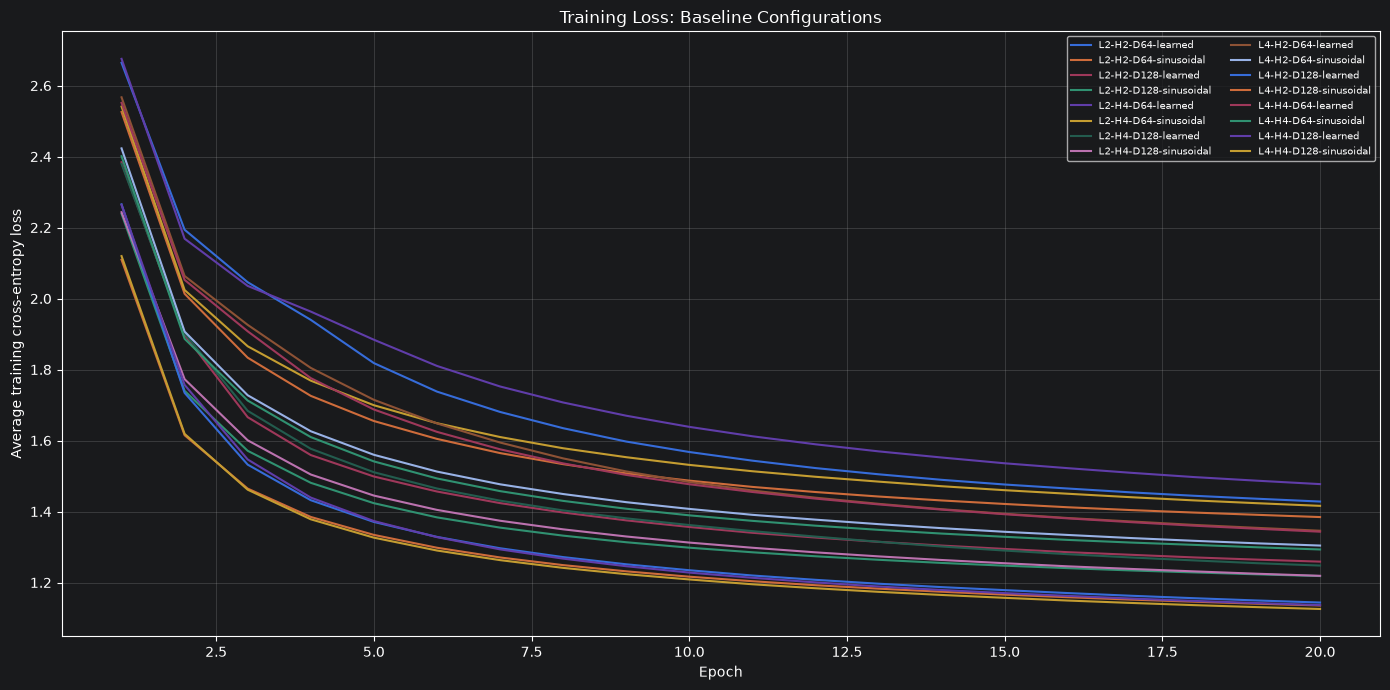

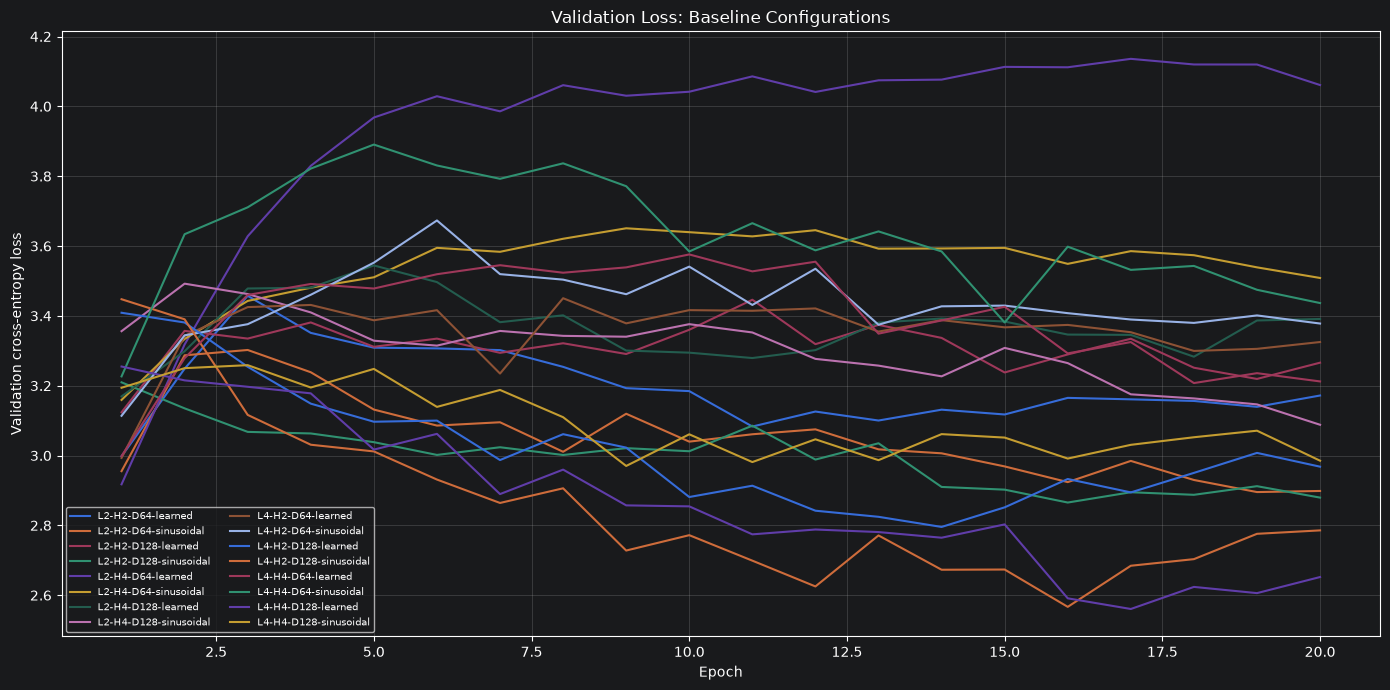

In [19]:
plt.figure(figsize=(14, 7))
for row in results:
    label = f"L{row['layers']}-H{row['heads']}-D{row['d_model']}-{row['position']}"
    plt.plot(range(1, len(row["train_history"])+1), row["train_history"], label=label)
plt.xlabel("Epoch")
plt.ylabel("Average training cross-entropy loss")
plt.title("Training Loss: Baseline Configurations")
plt.legend(fontsize=7, ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("task2_outputs/baseline_training_loss.png", dpi=160)
plt.show()

plt.figure(figsize=(14, 7))
for row in results:
    label = f"L{row['layers']}-H{row['heads']}-D{row['d_model']}-{row['position']}"
    plt.plot(range(1, len(row["val_history"])+1), row["val_history"], label=label)
plt.xlabel("Epoch")
plt.ylabel("Validation cross-entropy loss")
plt.title("Validation Loss: Baseline Configurations")
plt.legend(fontsize=7, ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("task2_outputs/baseline_validation_loss.png", dpi=160)
plt.show()

## Validation summary table and best configuration

In [20]:
summary = results_df[["layers","heads","d_model","position","train_loss","val_loss","perplexity","seconds_per_epoch","total_seconds"]].copy()
summary = summary.sort_values("val_loss").reset_index(drop=True)
display(summary.round(4))
summary.to_csv("task2_outputs/baseline_summary.csv", index=False)

best_row = results_df.loc[results_df["val_loss"].idxmin()]
best_config = {k: best_row[k] for k in ["layers","heads","d_model","position"]}
best_key = (int(best_config["layers"]), int(best_config["heads"]), int(best_config["d_model"]), best_config["position"])
best_model = models[best_key]
print("Best configuration:", best_config)
print("Validation loss:", round(float(best_row["val_loss"]), 4))
print("Validation perplexity:", round(float(best_row["perplexity"]), 4))

,layers,heads,d_model,position,train_loss,val_loss,perplexity,seconds_per_epoch,total_seconds
0,4,4,128,learned,1.1363,2.6520,14.1831,28.3258,566.5164
1,4,2,128,sinusoidal,1.1353,2.7856,16.2100,24.3218,486.4352
2,2,2,128,sinusoidal,1.2182,2.8795,17.8052,11.9214,238.4276
3,2,2,64,sinusoidal,1.3844,2.8985,18.1474,8.0900,161.8000
4,4,2,128,learned,1.1436,2.9680,19.4538,22.8603,457.2066
5,4,4,128,sinusoidal,1.1254,2.9852,19.7899,27.8502,557.0033
6,2,4,128,sinusoidal,1.2189,3.0881,21.9352,14.4512,289.0235
7,2,2,64,learned,1.4281,3.1719,23.8525,8.0503,161.0055
8,4,4,64,learned,1.3432,3.2122,24.8333,20.2764,405.5282
9,2,2,128,learned,1.2588,3.2659,26.2042,12.0060,240.1192


Best configuration: {'layers': np.int64(4), 'heads': np.int64(4), 'd_model': np.int64(128), 'position': 'learned'}
Validation loss: 2.652
Validation perplexity: 14.1831


## Bonus: depth scaling study (2, 4, 6 and 8 blocks)

In [21]:
depth_results = []
depth_models = {}
for layers in [2, 4, 6, 8]:
    config = {"layers": layers, "heads": 4, "d_model": 128, "position": "learned"}
    print("\nDepth study:", config)
    model, train_hist, val_hist, seconds = train_model(config, f"depth_{layers}")
    depth_models[layers] = model
    depth_results.append({
        **config, "train_history": train_hist, "val_history": val_hist,
        "train_loss": train_hist[-1], "val_loss": val_hist[-1],
        "perplexity": math.exp(min(val_hist[-1], 20)),
        "seconds_per_epoch": seconds / len(train_hist),
        "total_seconds": seconds
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df[["layers","heads","d_model","train_loss","val_loss","perplexity","seconds_per_epoch","total_seconds"]].round(4))
depth_df[["layers","heads","d_model","train_loss","val_loss","perplexity","seconds_per_epoch","total_seconds"]].to_csv("task2_outputs/depth_scaling_summary.csv", index=False)


Depth study: {'layers': 2, 'heads': 4, 'd_model': 128, 'position': 'learned'}
Epoch 01 | train loss 2.3775 | val loss 3.1613 | val PPL 23.60
Epoch 02 | train loss 1.9381 | val loss 3.2755 | val PPL 26.46
Epoch 03 | train loss 1.7068 | val loss 3.2718 | val PPL 26.36
Epoch 04 | train loss 1.5706 | val loss 3.3083 | val PPL 27.34
Epoch 05 | train loss 1.4925 | val loss 3.2531 | val PPL 25.87
Epoch 06 | train loss 1.4414 | val loss 3.2125 | val PPL 24.84
Epoch 07 | train loss 1.4040 | val loss 3.1984 | val PPL 24.49
Epoch 08 | train loss 1.3756 | val loss 3.1775 | val PPL 23.99
Epoch 09 | train loss 1.3532 | val loss 3.0988 | val PPL 22.17
Epoch 10 | train loss 1.3353 | val loss 3.1636 | val PPL 23.65
Epoch 11 | train loss 1.3198 | val loss 3.1457 | val PPL 23.24
Epoch 12 | train loss 1.3070 | val loss 3.1358 | val PPL 23.01
Epoch 13 | train loss 1.2954 | val loss 3.1698 | val PPL 23.80
Epoch 14 | train loss 1.2853 | val loss 3.0409 | val PPL 20.92
Epoch 15 | train loss 1.2765 | val loss

,layers,heads,d_model,train_loss,val_loss,perplexity,seconds_per_epoch,total_seconds
0,2,4,128,1.2415,2.9678,19.4483,14.6570,293.1401
1,4,4,128,1.1330,2.8210,16.7931,28.0688,561.3757
2,6,4,128,1.0943,3.1334,22.9515,42.0721,841.4413
3,8,4,128,1.0669,3.0056,20.1981,54.4561,1089.1225


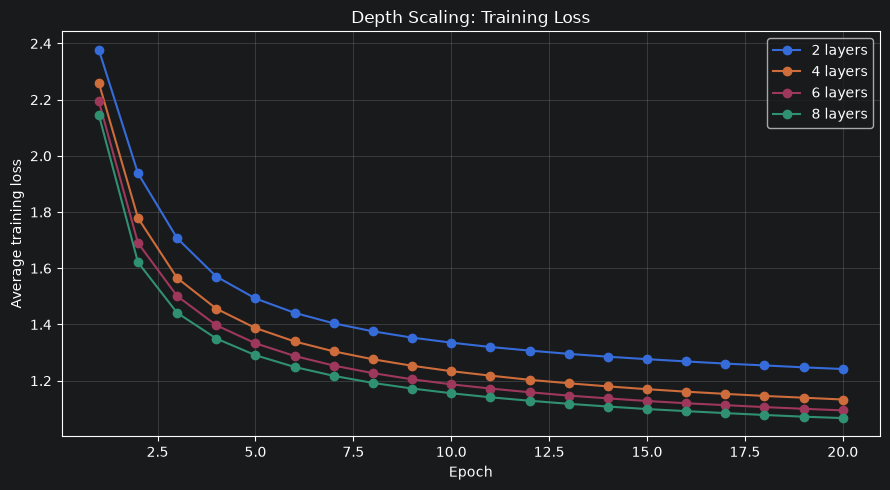

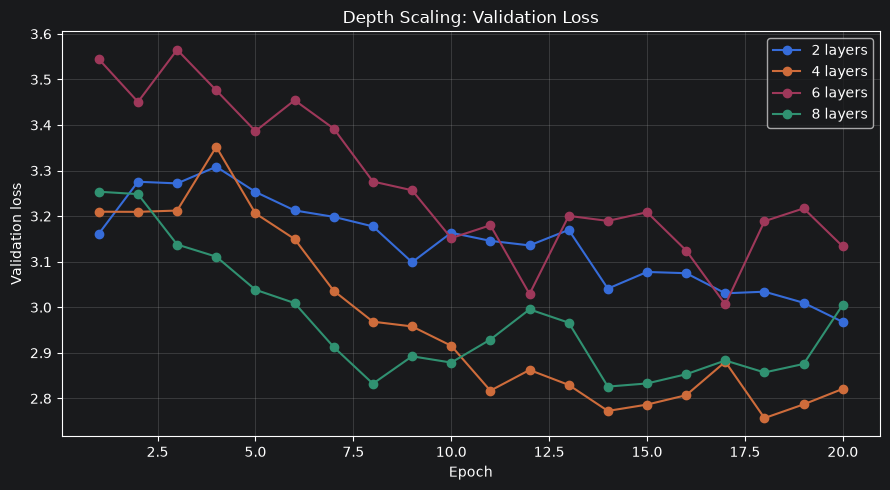

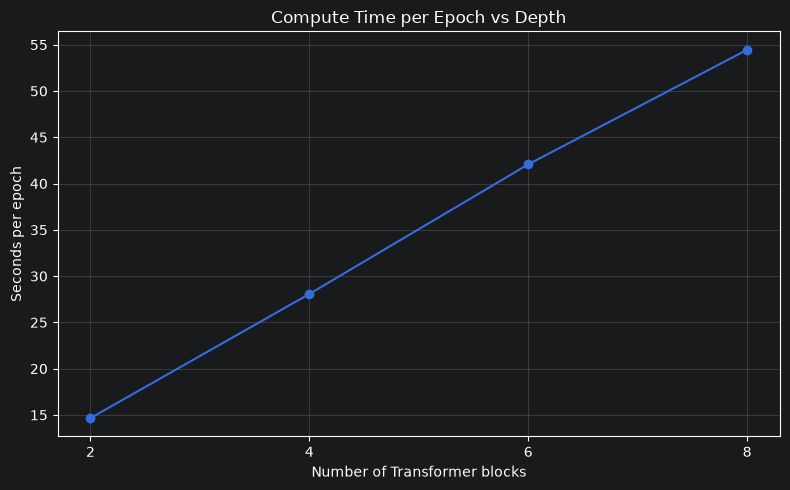

In [22]:
plt.figure(figsize=(9, 5))
for row in depth_results:
    plt.plot(range(1, len(row["train_history"])+1), row["train_history"], marker="o", label=f"{row['layers']} layers")
plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.title("Depth Scaling: Training Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("task2_outputs/depth_training_loss.png", dpi=160)
plt.show()

plt.figure(figsize=(9, 5))
for row in depth_results:
    plt.plot(range(1, len(row["val_history"])+1), row["val_history"], marker="o", label=f"{row['layers']} layers")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Depth Scaling: Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("task2_outputs/depth_validation_loss.png", dpi=160)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(depth_df["layers"], depth_df["seconds_per_epoch"], marker="o")
plt.xlabel("Number of Transformer blocks")
plt.ylabel("Seconds per epoch")
plt.title("Compute Time per Epoch vs Depth")
plt.xticks([2, 4, 6, 8])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("task2_outputs/depth_runtime.png", dpi=160)
plt.show()

## Text generation: greedy and temperature sampling

In [23]:
@torch.no_grad()
def generate(model, prompt, max_new_tokens=300, temperature=None):
    model.eval()
    prompt_ids = encode(prompt)
    if not prompt_ids:
        prompt_ids = [0]
    idx = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)
    for _ in range(max_new_tokens):
        context = idx[:, -SEQ_LEN:]
        logits, _ = model(context)
        next_logits = logits[:, -1, :]
        if temperature is None:
            next_id = torch.argmax(next_logits, dim=-1, keepdim=True)
        else:
            scaled_logits = next_logits / temperature
            probs = F.softmax(scaled_logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
        idx = torch.cat([idx, next_id], dim=1)
    model.train()
    return decode(idx[0].tolist())

prompts = [
    "To be, or not to be",
    "KING: My lord",
    "ROMEO:",
    "What is the cause",
    "The night is dark"
]

In [24]:
generation_rows = []
for prompt in prompts:
    greedy_text = generate(best_model, prompt, 250, None)
    generation_rows.append({"prompt": prompt, "decoding": "greedy", "temperature": "N/A", "generated_text": greedy_text})
    for temp in [0.5, 0.8, 1.2]:
        sample = generate(best_model, prompt, 250, temp)
        generation_rows.append({"prompt": prompt, "decoding": "sampling", "temperature": temp, "generated_text": sample})

generation_df = pd.DataFrame(generation_rows)
for _, row in generation_df.iterrows():
    print("\n" + "="*70)
    print("Prompt:", row["prompt"], "|", row["decoding"], "| temperature:", row["temperature"])
    print(row["generated_text"])
generation_df.to_csv("task2_outputs/generated_samples.csv", index=False)


Prompt: To be, or not to be | greedy | temperature: N/A
To be, or not to be so much a strange of the sea,"
"And the strange of the stranger of the state,"
"And the strange of the stranger of the state,"
"And the stranger of the state of the state,"
"And the stranger of the state of the state,"
"And the stranger of the state

Prompt: To be, or not to be | sampling | temperature: 0.5
To be, or not to bear this hand, and there that I"
"see your love is a shamed light of this revenge before,"
"That you have to the sun ask of his honour."
"If you shall be show'd a gallow shall not."
"If you should profess to my sovereign,"
"And then her that I will co

Prompt: To be, or not to be | sampling | temperature: 0.8
To be, or not to be swelled fall."
"Why, thy gracious shall needs to your shall charge cestrain,"
"conveites I will not have never stranges,"
"And then we would drunk thee like it the bawdy,"
"The brows about, for my sunself."
"Exeunt Brook, Trandilia, you shall wither

Prompt: To be,

## 4 × 4 generation comparison grid

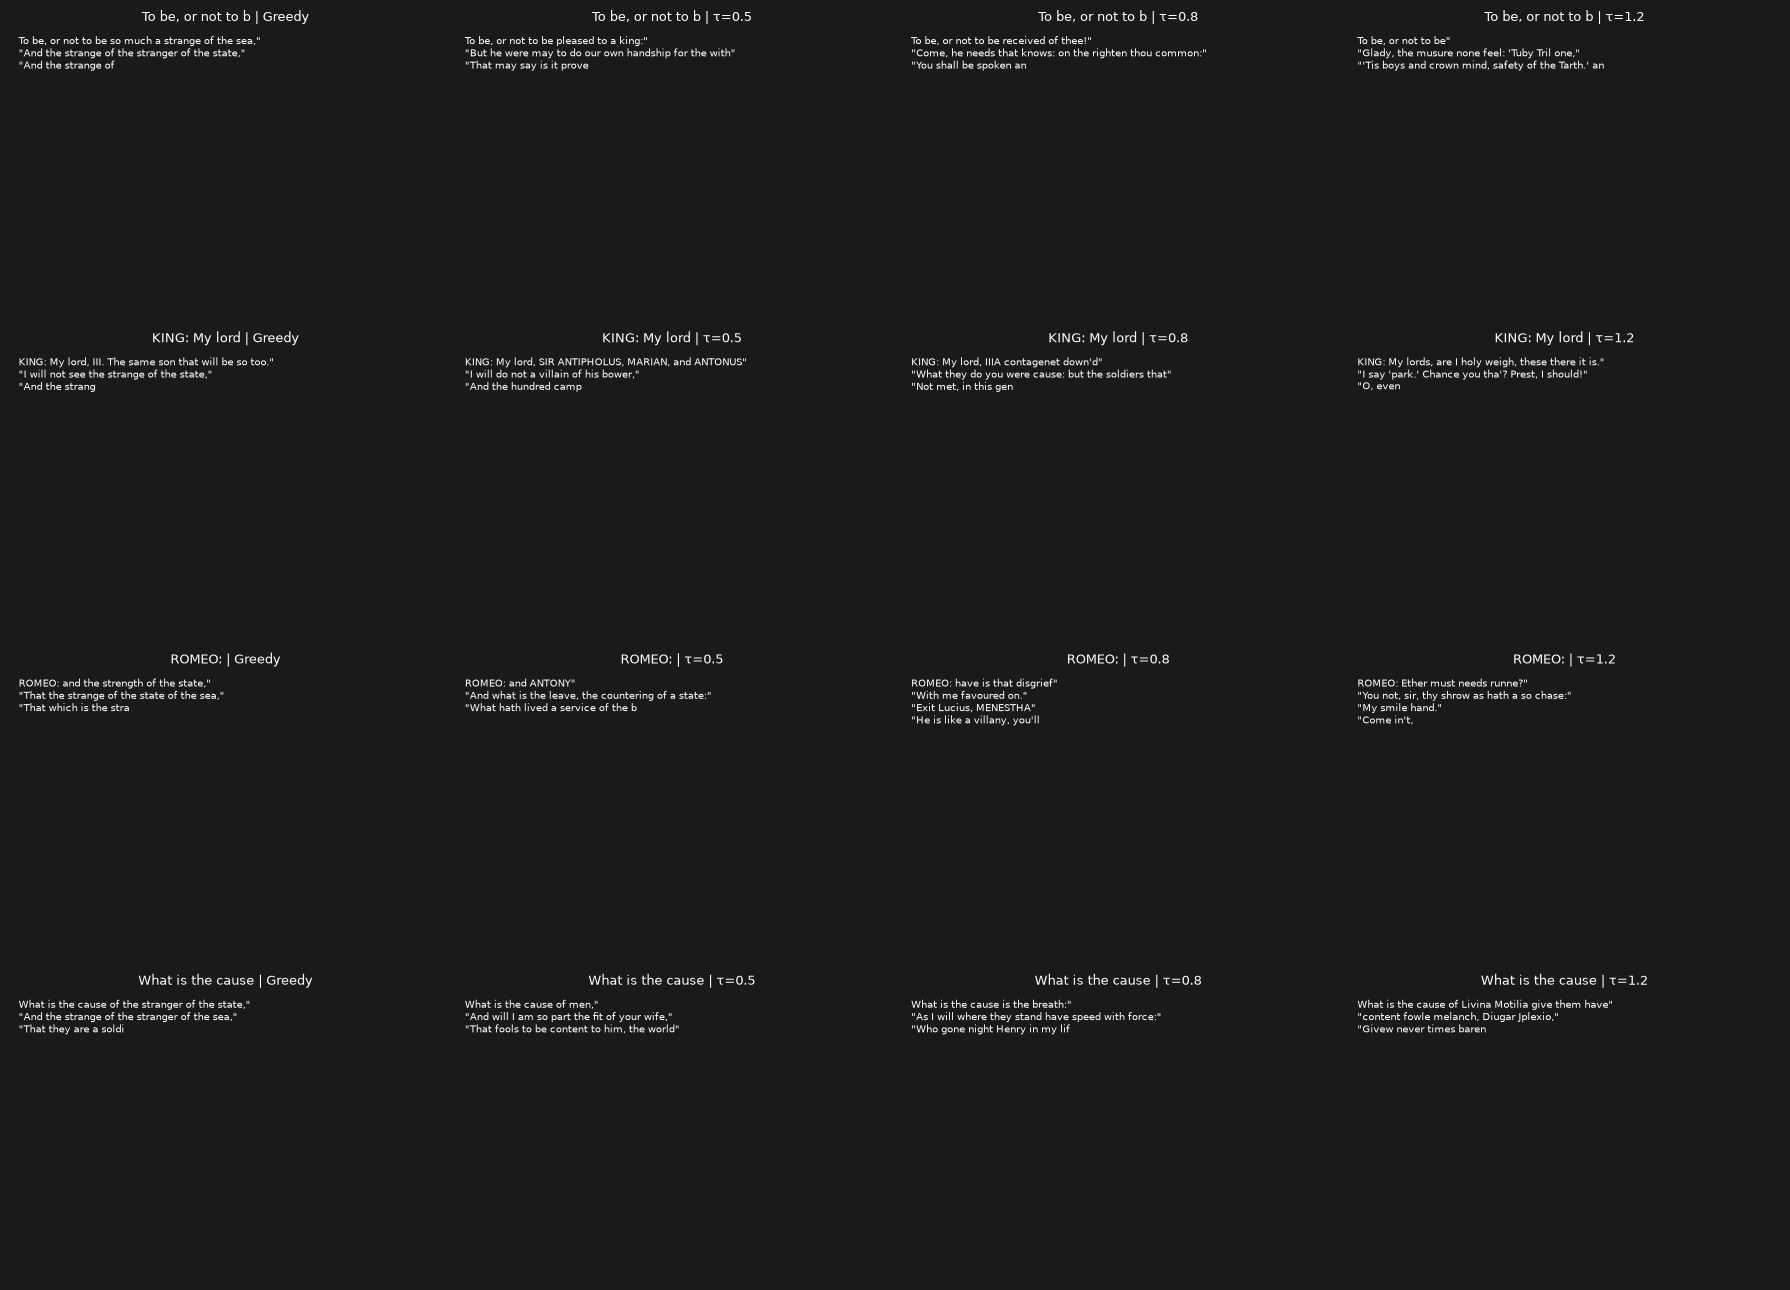

In [25]:
grid_prompts = prompts[:4]
grid_modes = [("Greedy", None), ("τ=0.5", 0.5), ("τ=0.8", 0.8), ("τ=1.2", 1.2)]
fig, axes = plt.subplots(4, 4, figsize=(18, 13))
for r, prompt in enumerate(grid_prompts):
    for c, (label, temp) in enumerate(grid_modes):
        sample = generate(best_model, prompt, 100, temp)
        axes[r, c].text(0.02, 0.98, sample, va="top", ha="left", wrap=True, fontsize=7)
        axes[r, c].set_title(f"{prompt[:18]} | {label}", fontsize=9)
        axes[r, c].axis("off")
plt.tight_layout()
plt.savefig("task2_outputs/generation_grid_4x4.png", dpi=160)
plt.show()

## Causal attention heatmap

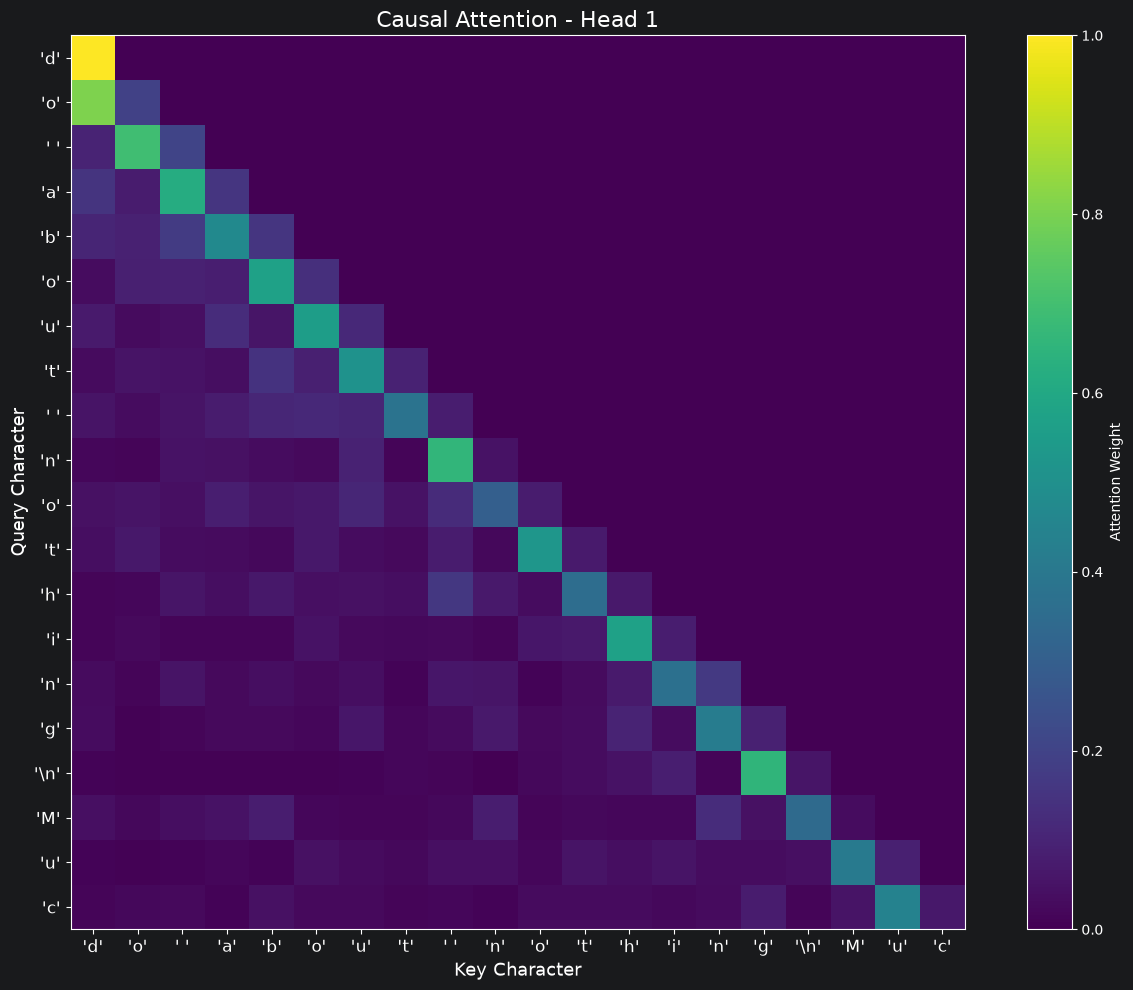

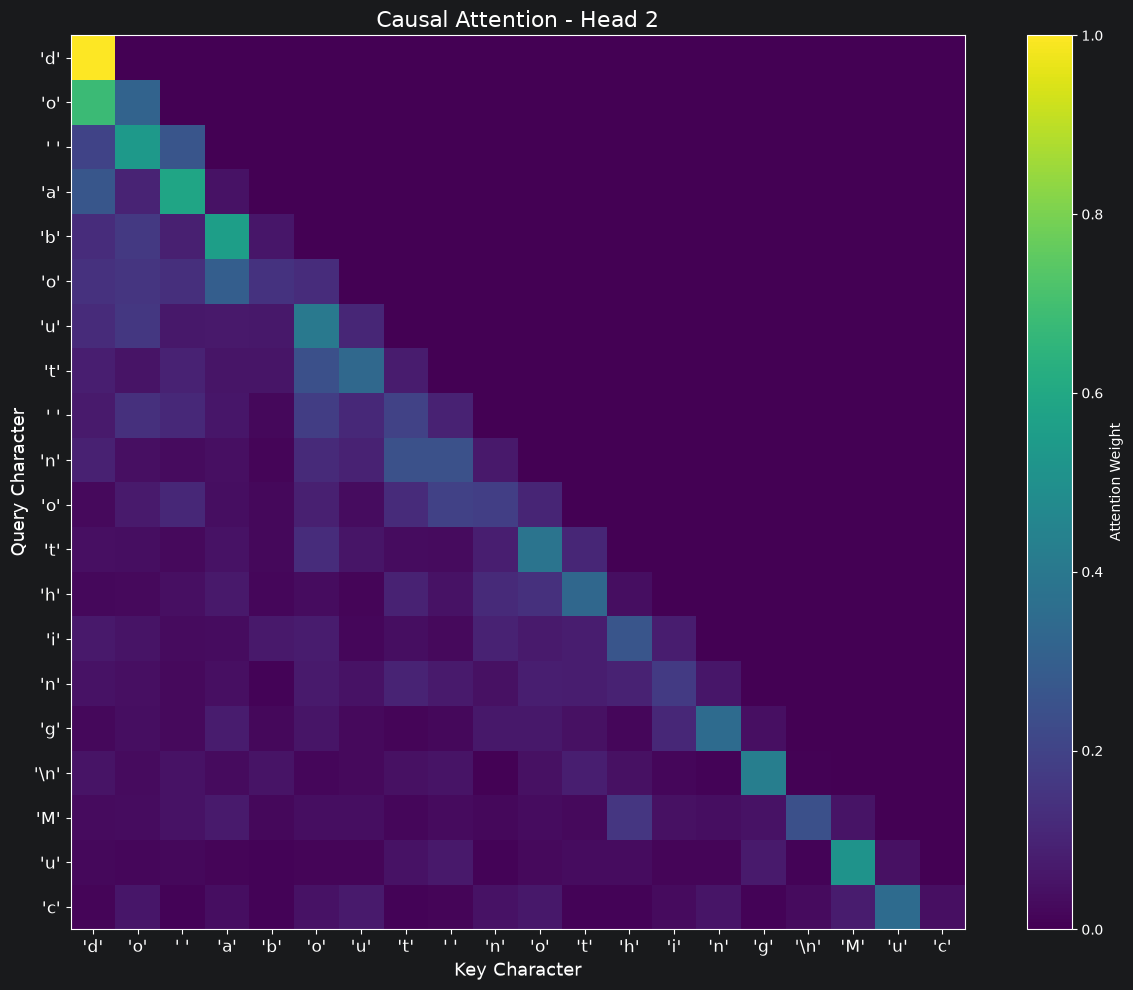

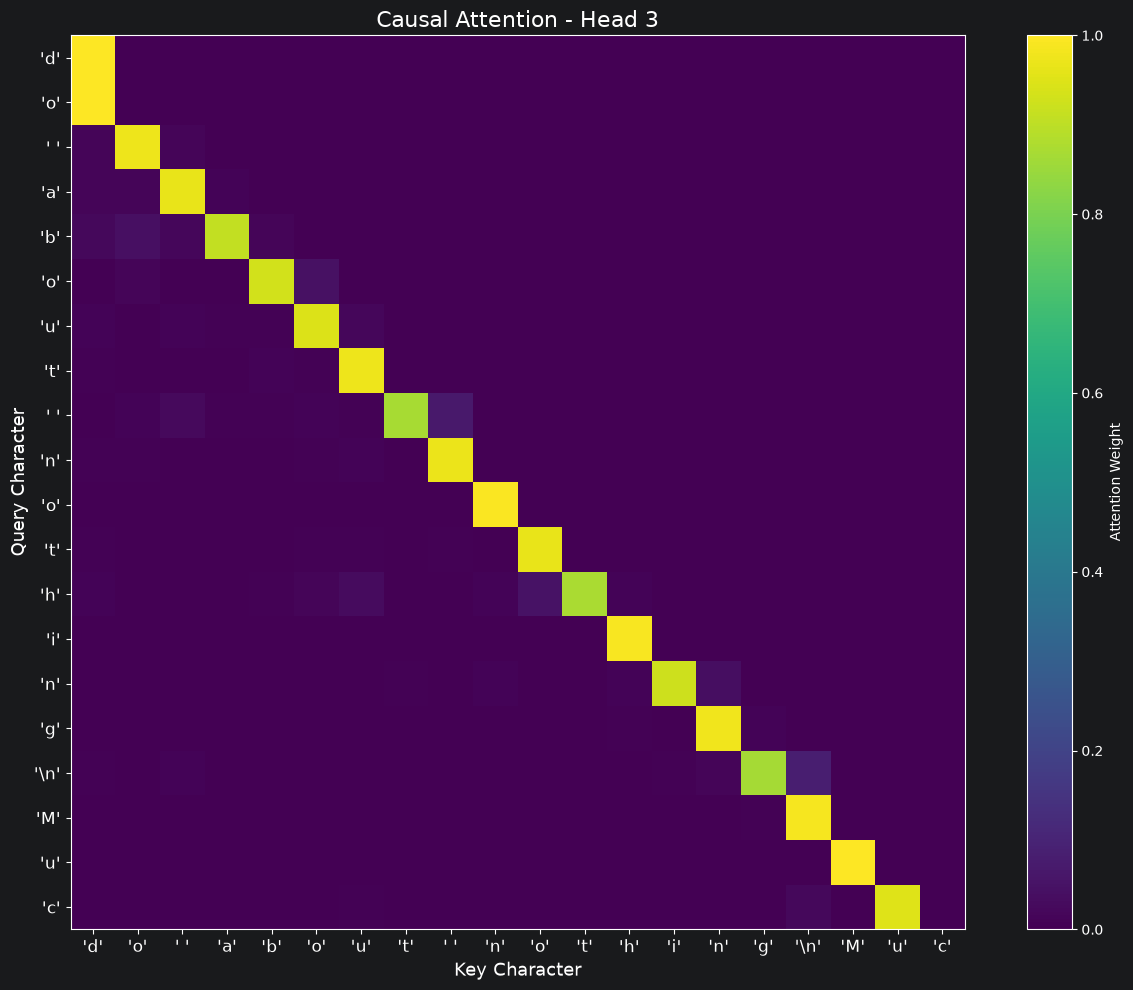

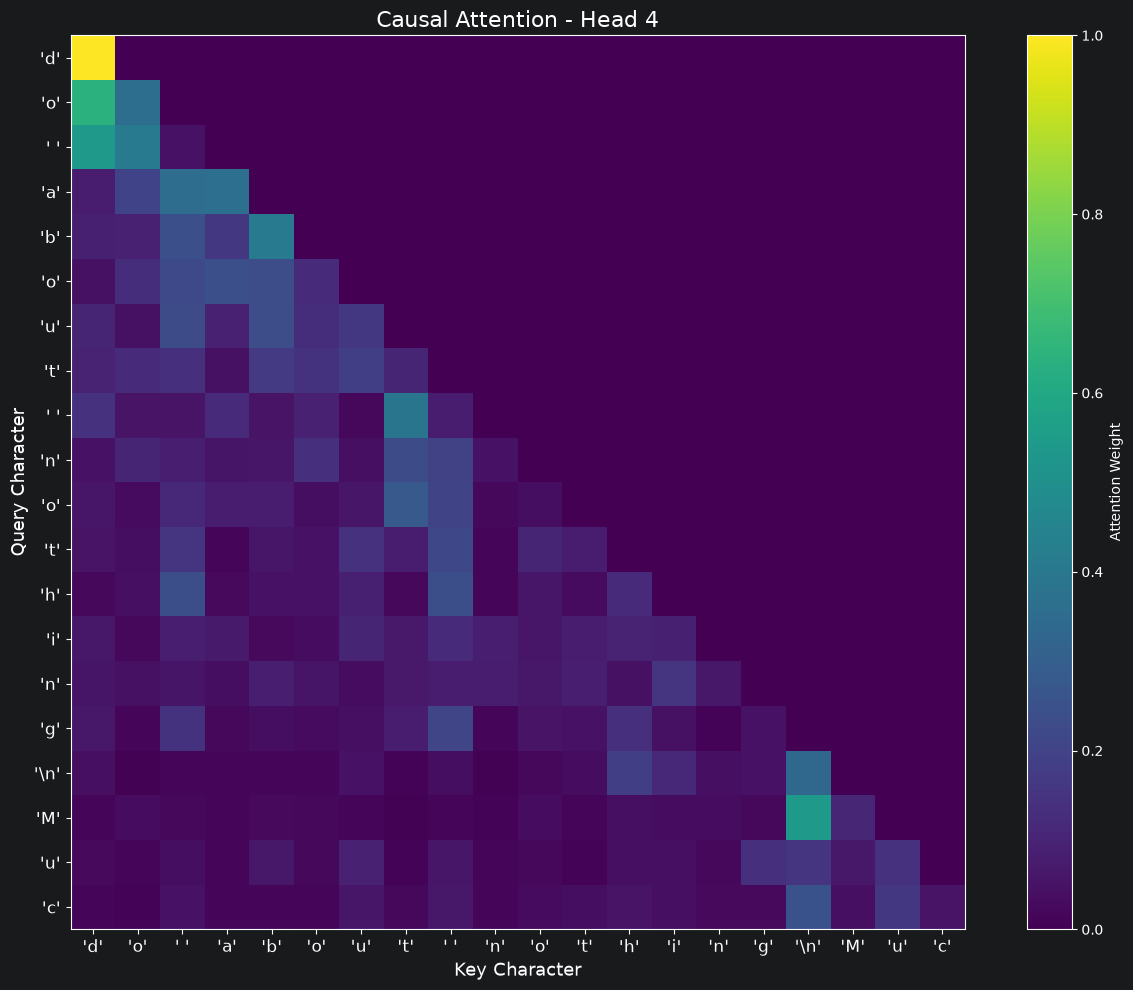

In [29]:
best_model.eval()

sample_x, _ = next(iter(val_loader))
sample_x = sample_x[:1].to(DEVICE)

with torch.no_grad():
    _, _, attention = best_model(sample_x, return_attention=True)

n = 20
tokens = sample_x[0, :n].cpu().tolist()
labels = [repr(itos[i]) for i in tokens]

heads = attention.shape[1]

for h in range(heads):
    attn = attention[0, h, :n, :n].cpu().numpy()

    plt.figure(figsize=(13, 10))
    plt.imshow(attn, cmap="viridis", aspect="equal")
    plt.colorbar(label="Attention Weight")

    plt.title(f"Causal Attention - Head {h+1}", fontsize=16)
    plt.xlabel("Key Character", fontsize=13)
    plt.ylabel("Query Character", fontsize=13)

    plt.xticks(range(n), labels, fontsize=12)
    plt.yticks(range(n), labels, fontsize=12)

    plt.tight_layout()
    plt.savefig(f"task2_outputs/head_{h+1}_large.png", dpi=250)
    plt.show()
